# 9g. What distinguishes an SSW member from comparable members that do not reverse?

An event-mechanism study of one simulated SSW: the **featured member** (`EVENT`, chosen by hand) against
two controls from the same start and winter, both without an SSW:

* **matched member**: the closest pre-onset vortex state (mean U(60°N, 10 hPa) over `MATCH_WINDOW`
  days before the featured central date);
* **near-miss member**: the strongest weakening that does not reverse (lowest minimum U(60°N, 10 hPa)
  within `NEAR_WINDOW` days of the central date). It is chosen **from its later outcome**, so it is a
  descriptive control, not an independent prediction test.

Then: aligned timelines (raw U(60°N, 10 hPa), 10-hPa polar-cap temperature, 100-hPa heat flux) over
`EVENT_WINDOW`; where the featured member ranks among all members of its start; **whether the featured
trajectory reflects an ensemble relationship** (preconditioning and pre-onset wave activity against the
outcome, every member); pre-onset 10-hPa height maps (`PRE_WINDOWS`); and a side-by-side animation.

**Interpretation caution.** These comparisons identify precursors and a plausible mechanism; they do not
prove what caused the SSW. Similar U(60°N, 10 hPa) does not mean identical preconditioning (vertical wind
structure, vortex geometry and wave-propagation conditions can differ). The 100-hPa heat flux is a proxy for
upward wave activity, not the momentum forcing at 10 hPa (EP-flux convergence would be closer; it needs the
eddy momentum flux, which the model cache does not hold). The model flux is the eddy covariance of daily-mean
fields, so sub-daily contributions are missing: compare members with one another (same sampling), not with
the magnitude of the differently sampled ERA5 flux. Polar-cap temperature is an area mean and U(60°N) one
latitude ring, so they need not move together; vortex geometry matters.

For the broad seasonal view see 9i (fixed members, no event-based selection) and 9h (selected SSW members).

**The 9a-9i series** (polar vortex and SSWs in the RTENSO2026 2026 starts): `9a` builds and checks the
caches; `9b` model climatology; `9c` vortex forecast; `9d` SSW occurrence; `9e` ENSO/QBO background;
`9f` SSW dynamics; `9g` SSW mechanism (featured member vs controls); `9h` SSW-event animation; `9i`
seasonal-evolution animation. Shared loading: `util/strat_diag.py`; readers `util/strat_case.py`; maps
`util/vortex_plot.py`.

In [1]:
%matplotlib inline

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from util import rtenso_case as rc
from util import strat_case as sc
from util import strat_diag as sd

warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")

from matplotlib import animation
from esp_lab.utils.filename_utils import figure_filename
from util import vortex_plot as vp

### Run controls

In [2]:
NOTEBOOK = "9g_ssw_mechanism"   # outputs: rc.OUTPUT_ROOT/9g_ssw_mechanism/{figures,data}/
# "require": read the caches built by 9a only; "auto": build a missing cache; "rebuild": recompute
derivation_mode = "require"
CLIM_METHOD = "direct"      # model climatology: "direct" (each start's Reanalysis starts; Feb/Aug 1985-2010), "lead_drift"
WORKERS = 4                 # processes reading model output (cache builds only; login node: 30 GB per user)

# Data locations (machine-specific)
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                       # reference-data archive
ERA5_ZONAL_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily_zonal"                    # ERA5 daily zonal means
ERA5_DAILY_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily"                          # ERA5 daily maps (PSL)
SIMULATION_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/simulation")         # raw eam.h1 history

cfg = sd.StratConfig(era5_zonal_dir=ERA5_ZONAL_DIR, era5_daily_dir=ERA5_DAILY_DIR, simulation_root=SIMULATION_ROOT,
                     clim_method=CLIM_METHOD, mode=derivation_mode, workers=WORKERS)
YEAR, INIT_MONTHS, POOL, CLIM_YEARS = cfg.year, cfg.init_months, cfg.pool, cfg.clim_years
ERA5_FIRST_YEAR, REF_LEVEL, SSW = cfg.era5_first_year, cfg.ref_level, cfg.ssw
MONTH_NAMES, INIT_COLORS, MODEL_PREFIX = sd.MONTH_NAMES, sd.INIT_COLORS, rc.MODEL_PREFIX
MAP_FILE = Path("/global/cfs/cdirs/e3sm/diagnostics/maps/map_ne30pg2_to_cmip6_180x360_aave.20200201.nc")
EVENT = {"init": 8, "member": "Reanalysis-CLIM:9", "winter": 2026}   # featured SSW member (its first SSW of the winter)
MATCH_WINDOW = (-40, -21)          # days before the central date: matched member = closest mean U(60N, 10 hPa)
NEAR_WINDOW = (-15, 15)            # days around the central date: near-miss = lowest minimum U60 without reversal
EVENT_WINDOW = (-30, 30)           # timelines and animation
PRE_WINDOWS = [(-20, -11), (-10, -1)]   # pre-onset map averages and ranks
RANK_WINDOW = (-20, -1)            # pre-onset window of the ensemble ranks (and the wave activity of section 4)
PRECOND_WINDOW = (-30, -21)        # preconditioning: mean U(60N, 10 hPa)
OUTCOME_WINDOW = (0, 10)           # outcome: minimum U(60N, 10 hPa)
ROLES = {"featured": "#d62728", "matched": "#1f77b4", "near-miss": "#ff7f0e"}
LAT_MIN = 30.0
STYLE = {"ci": 100.0, "range": 1200.0, "cmap": "blue2red", "units": "m", "name": "10-hPa height anomaly",
         "line": 400.0, "line_levels": np.arange(26000.0, 33000.0, 400.0)}
FPS, HOLD, ANIM_DPI, ANIM_FORMATS = 5, 5, 100, ("gif", "video")
FIGDIR = rc.figure_dir(NOTEBOOK)

fontz = 13
fig_type = "png"
fig_dpi = 200
plt.rcParams.update({"font.size": fontz, "axes.titlesize": fontz, "axes.labelsize": fontz,
                     "legend.fontsize": fontz * 0.8, "xtick.labelsize": fontz * 0.85, "ytick.labelsize": fontz * 0.85})
rng = np.random.default_rng(0)


def save(fig, *parts):
    path = rc.save_figure(fig, NOTEBOOK, *parts, dpi=fig_dpi, ext=fig_type)
    print(f"[FIGURE] {path}")


DATA_DIR = rc.output_dir(NOTEBOOK, "data")

### Load

In [3]:
%%time
E = sd.load_era5(cfg)                         # ERA5 daily zonal-mean indices and climatologies (cached)
era5, obs_end = E.fields, E.obs_end
e_u60, e_pcz, e_pct, e_vt, e_qbo, e_pch = E.u60, E.pcz, E.pct, E.vt, E.qbo, E.pch
clim_u60, std_u60, clim_pcz, std_pcz = E.clim_u60, E.std_u60, E.clim_pcz, E.std_pcz
e_month_clim, e_u60_month = E.month_clim, E.u60_month
on_days = sd.on_days

ERA5 daily zonal means 01 Jan 1979 - 30 Jun 2026
CPU times: user 2.9 s, sys: 1.02 s, total: 3.92 s
Wall time: 47.4 s


In [4]:
R = sd.load_references(cfg)                   # Reanalysis monthly zonal means of every start month
ref, ref_direct, REF_ALL, MPLEV = R.ref, R.direct, R.all, R.plev
e_month_clim_m = e_month_clim.sel(plev=MPLEV)   # ERA5 on the model monthly levels

In [5]:
%%time
M = sd.load_model(cfg, E, R)                  # pooled 2026 starts: zonal means, climatologies, daily indices
monthly, daily, lead_clim, z_offset = M.monthly, M.daily, M.lead_clim, M.z_offset
m_u60, m_u60_clim, m_u60_adj, m_pch, m_vt = M.u60, M.u60_clim, M.u60_adj, M.pch, M.vt
mm_u60, mm_u60_anom, mm_qbo = M.mm_u60, M.mm_u60_anom, M.mm_qbo

[init Feb 2026] 20 members, daily 01 Feb 2026 - 31 Jan 2028; climatology: Reanalysis init02 6 starts 1985-2010 (every fifth year)


[init May 2026] 30 members, daily 01 May 2026 - 30 Apr 2028; climatology: Reanalysis init05 1981-2010


[init Aug 2026] 30 members, daily 01 Aug 2026 - 31 Jul 2028; climatology: Reanalysis init08 6 starts 1985-2010 (every fifth year)


[init Nov 2026] 30 members, daily 01 Nov 2026 - 31 Oct 2028; climatology: Reanalysis init11 1981-2010
CPU times: user 3.14 s, sys: 1.7 s, total: 4.85 s
Wall time: 26.8 s


In [6]:
C = sd.ssw_catalogue(cfg, E, M)               # SSW central dates and event properties (raw and bias-adjusted)
obs_events, obs_winters, obs_counts = C.obs_events, C.obs_winters, C.obs_counts
model_ssw, model_ssw_adj, events_all = C.model_ssw, C.model_ssw_adj, C.events
mid_month, case_of, djf_mean, DJF_DAYS = sd.mid_month, sd.case_of, sd.djf_mean, sd.DJF_DAYS

### 1. The featured event and its controls

The featured member's first SSW of the winter sets day 0. Controls are drawn from the members of the
same start with no SSW in that winter (raw wind).

In [7]:
init, feat, w = EVENT["init"], EVENT["member"], EVENT["winter"]
u, t10, vt = m_u60[init], M.pct[init], m_vt[init]
times = pd.DatetimeIndex(u["time"].values)
ev = model_ssw[init]
ev_feat = ev[(ev["series"] == feat) & (ev["winter"] == w)]
if ev_feat.empty:
    raise ValueError(f"{feat} has no SSW in {sd.winter_label(w)} (start {MONTH_NAMES[init]}); choose another EVENT")
day0 = pd.Timestamp(ev_feat["central_date"].iloc[0])
ssw_members = set(ev[ev["winter"] == w]["series"])
controls_pool = [str(m) for m in u["member"].values if str(m) not in ssw_members]


def window(da, lo, hi):
    return da.sel(time=slice(day0 + pd.Timedelta(days=lo), day0 + pd.Timedelta(days=hi)))


pre_match = window(u, *MATCH_WINDOW).mean("time").to_series()
near_min = window(u, *NEAR_WINDOW).min("time").to_series()
matched = (pre_match[controls_pool] - pre_match[feat]).abs().idxmin()
near = near_min[[m for m in controls_pool if m != matched]].idxmin()
MEMBERS = {"featured": feat, "matched": matched, "near-miss": near}
print(f"Featured {feat}, start {MONTH_NAMES[init]} {YEAR}: SSW central date {day0:%d %b %Y}; "
      f"{len(ssw_members)} of {u.sizes['member']} members have an SSW in {sd.winter_label(w)}, {len(controls_pool)} controls")
summary = pd.DataFrame({role: {
    f"U60 mean, days {MATCH_WINDOW[0]} to {MATCH_WINDOW[1]} (m/s)": pre_match[m],
    f"U60 mean, days {RANK_WINDOW[0]} to {RANK_WINDOW[1]} (m/s)": float(window(u.sel(member=m), *RANK_WINDOW).mean()),
    f"[v*T*] 100 hPa mean, days {RANK_WINDOW[0]} to {RANK_WINDOW[1]} (K m/s)": float(window(vt.sel(member=m), *RANK_WINDOW).mean()),
    f"U60 minimum, days {NEAR_WINDOW[0]} to {NEAR_WINDOW[1]} (m/s)": near_min[m],
    "case": sd.case_of(m)} for role, m in MEMBERS.items()}).T.assign(member=list(MEMBERS.values()))
display(summary.round(1))

Featured Reanalysis-CLIM:9, start Aug 2026: SSW central date 06 Jan 2027; 10 of 30 members have an SSW in 2026/27, 20 controls


,"U60 mean, days -40 to -21 (m/s)","U60 mean, days -20 to -1 (m/s)","[v*T*] 100 hPa mean, days -20 to -1 (K m/s)","U60 minimum, days -15 to 15 (m/s)",case,member
featured,30.792892,18.269464,20.123603,-5.461871,Reanalysis-CLIM,Reanalysis-CLIM:9
matched,30.823613,37.216718,9.480749,25.837955,Reanalysis-OBS,Reanalysis-OBS:2
near-miss,23.68723,20.621267,14.347073,1.973329,Reanalysis-OBS,Reanalysis-OBS:4


### 2. Aligned timelines

Days from the featured central date. Thick lines: the three members; grey: the median and 10-90% range of
all members of the start. The heat flux is the daily-mean eddy covariance (5-day running mean thin line on top).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9g_ssw_mechanism/figures/fig_mechanism_timelines_aug_reanalysis_clim9.png


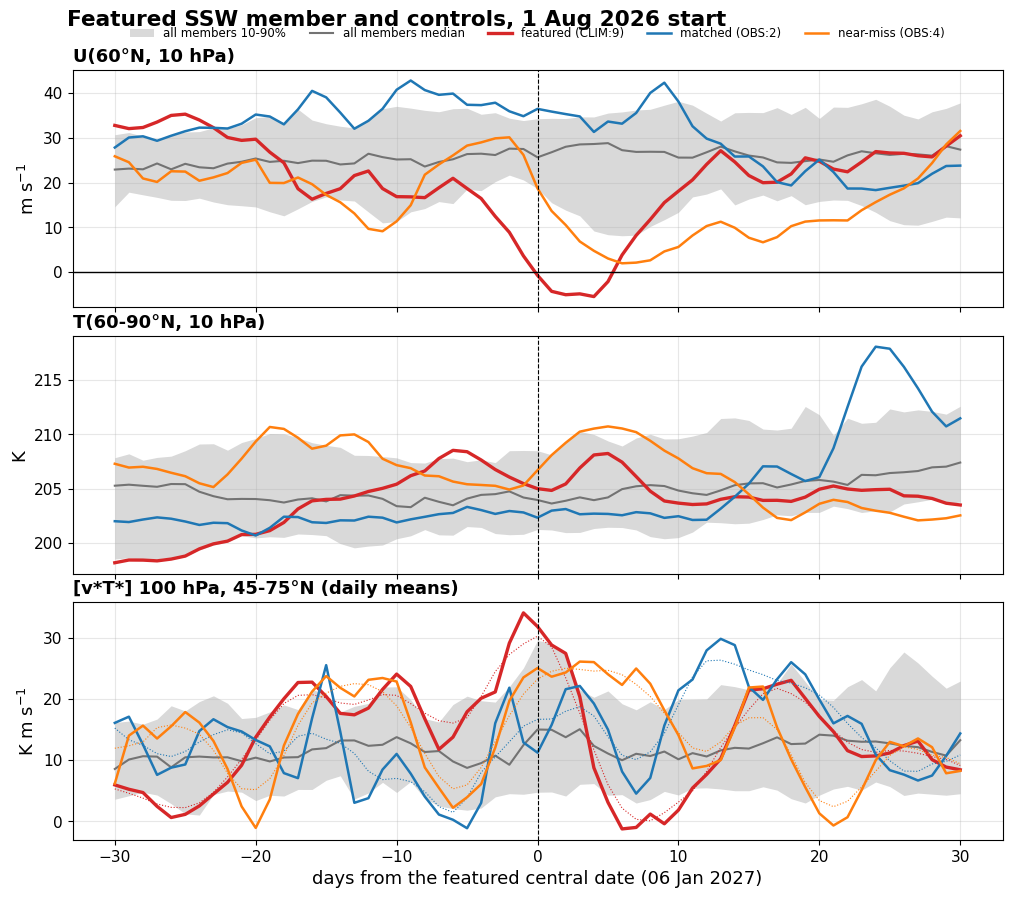

In [8]:
lags = np.arange(EVENT_WINDOW[0], EVENT_WINDOW[1] + 1)
lag_days = (day0 + pd.to_timedelta(lags, unit="D")).values


def on_lags(da):
    return da.sel(time=lag_days).assign_coords(time=lags).rename(time="lag")


fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={"hspace": 0.12})
for ax, (series, title, units) in zip(axes, [(u, "U(60°N, 10 hPa)", "m s$^{-1}$"), (t10, "T(60-90°N, 10 hPa)", "K"),
                                             (vt, "[v*T*] 100 hPa, 45-75°N (daily means)", "K m s$^{-1}$")]):
    s = on_lags(series)
    q = s.quantile([0.1, 0.5, 0.9], "member")
    ax.fill_between(lags, q.isel(quantile=0), q.isel(quantile=2), color="0.85", lw=0, label="all members 10-90%")
    ax.plot(lags, q.isel(quantile=1), color="0.45", lw=1.5, label="all members median")
    for role, m in MEMBERS.items():
        v = s.sel(member=m)
        ax.plot(lags, v, color=ROLES[role], lw=2.4 if role == "featured" else 1.8, label=f"{role} ({m.replace('Reanalysis-', '')})")
        if "v*T*" in title:
            ax.plot(lags, v.rolling(lag=5, center=True, min_periods=1).mean(), color=ROLES[role], lw=0.8, ls=":")
    if "U(60" in title:
        ax.axhline(0, color="k", lw=1)
    ax.axvline(0, color="k", lw=0.8, ls="--")
    ax.set_ylabel(units)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(alpha=0.3)
axes[0].legend(ncol=5, fontsize=fontz * 0.65, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.08))
axes[-1].set_xlabel(f"days from the featured central date ({day0:%d %b %Y})")
fig.suptitle(f"Featured SSW member and controls, 1 {MONTH_NAMES[init]} {YEAR} start", x=0.12, ha="left", y=0.94, fontweight="bold")
save(fig, "mechanism", "timelines", MONTH_NAMES[init], feat.replace(":", ""))
plt.show()

### 3. Where the featured member ranks in its ensemble

Pre-onset (`RANK_WINDOW`) mean U(60°N, 10 hPa) and 100-hPa heat flux of every member of the start: SSW
members (filled) and non-SSW members (open), the three compared members highlighted. A featured member at the
weak-wind, high-flux end supports a wave-driven precondition; one in the middle suggests chance.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9g_ssw_mechanism/figures/fig_mechanism_ensemble_ranks_aug_reanalysis_clim9.png


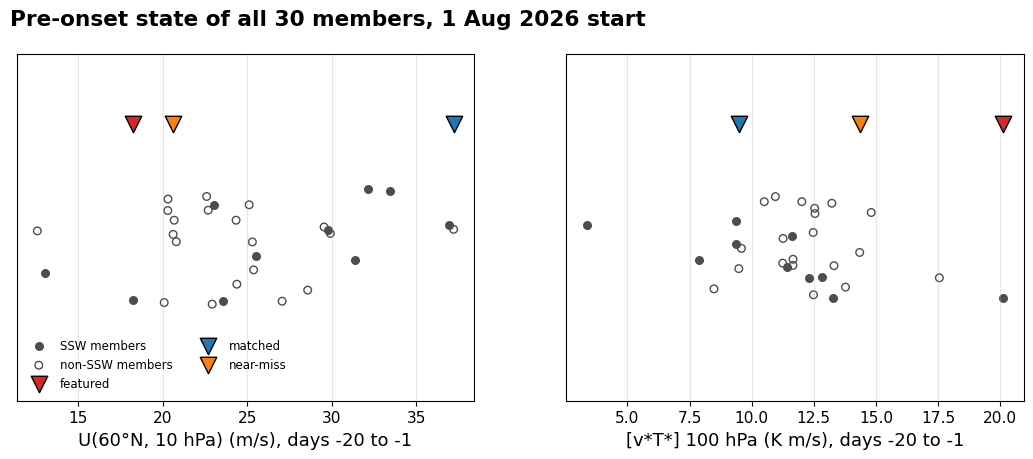

,quantity,role,member,value,rank (1 = lowest),of,percentile
0,"U(60°N, 10 hPa) (m/s)",featured,Reanalysis-CLIM:9,18.3,3,30,6.7
1,"U(60°N, 10 hPa) (m/s)",matched,Reanalysis-OBS:2,37.2,30,30,96.7
2,"U(60°N, 10 hPa) (m/s)",near-miss,Reanalysis-OBS:4,20.6,7,30,20.0
3,[v*T*] 100 hPa (K m/s),featured,Reanalysis-CLIM:9,20.1,30,30,96.7
4,[v*T*] 100 hPa (K m/s),matched,Reanalysis-OBS:2,9.5,6,30,16.7
5,[v*T*] 100 hPa (K m/s),near-miss,Reanalysis-OBS:4,14.3,27,30,86.7


In [9]:
pre_u = window(u, *RANK_WINDOW).mean("time").to_series()
pre_vt = window(vt, *RANK_WINDOW).mean("time").to_series()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rank_rows = []
for ax, (vals, label) in zip(axes, [(pre_u, "U(60°N, 10 hPa) (m/s)"), (pre_vt, "[v*T*] 100 hPa (K m/s)")]):
    order = vals.sort_values()
    y = rng.uniform(-0.15, 0.15, order.size)
    is_ssw = np.array([m in ssw_members for m in order.index])
    ax.scatter(order.values[is_ssw], y[is_ssw], color="0.3", s=30, label="SSW members")
    ax.scatter(order.values[~is_ssw], y[~is_ssw], facecolor="none", edgecolor="0.3", s=30, label="non-SSW members")
    for role, m in MEMBERS.items():
        ax.scatter([vals[m]], [0.32], marker="v", s=140, color=ROLES[role], edgecolor="k", zorder=5, label=role)
        rank_rows.append({"quantity": label, "role": role, "member": m, "value": vals[m],
                          "rank (1 = lowest)": int(order.index.get_loc(m)) + 1, "of": order.size,
                          "percentile": 100.0 * (order < vals[m]).mean()})
    ax.set_yticks([])
    ax.set_ylim(-0.4, 0.5)
    ax.set_xlabel(f"{label}, days {RANK_WINDOW[0]} to {RANK_WINDOW[1]}")
    ax.grid(alpha=0.3, axis="x")
axes[0].legend(fontsize=fontz * 0.65, frameon=False, ncol=2, loc="lower left")
fig.suptitle(f"Pre-onset state of all {u.sizes['member']} members, 1 {MONTH_NAMES[init]} {YEAR} start", x=0.12, ha="left", fontweight="bold")
save(fig, "mechanism", "ensemble_ranks", MONTH_NAMES[init], feat.replace(":", ""))
plt.show()
display(pd.DataFrame(rank_rows).round(1))

### 4. Is the featured member representative? The ensemble relationship

Every member of the start, on the featured member's calendar days: preconditioning (mean U(60°N, 10 hPa),
`PRECOND_WINDOW`) against pre-onset wave activity (mean 100-hPa heat flux, `RANK_WINDOW`), coloured by the
outcome (minimum U(60°N, 10 hPa), `OUTCOME_WINDOW`); filled markers have a qualifying SSW within the
outcome window, marker shapes are the cases. If members with more pre-onset wave activity on a weaker vortex
weaken more, the featured member is one instance of an ensemble relationship; otherwise it is one
illustrative trajectory. Spearman rank correlations quantify it (with 20-30 members, only strong
relationships are distinguishable from chance).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9g_ssw_mechanism/figures/fig_mechanism_ensemble_relationship_aug_reanalysis_clim9.png


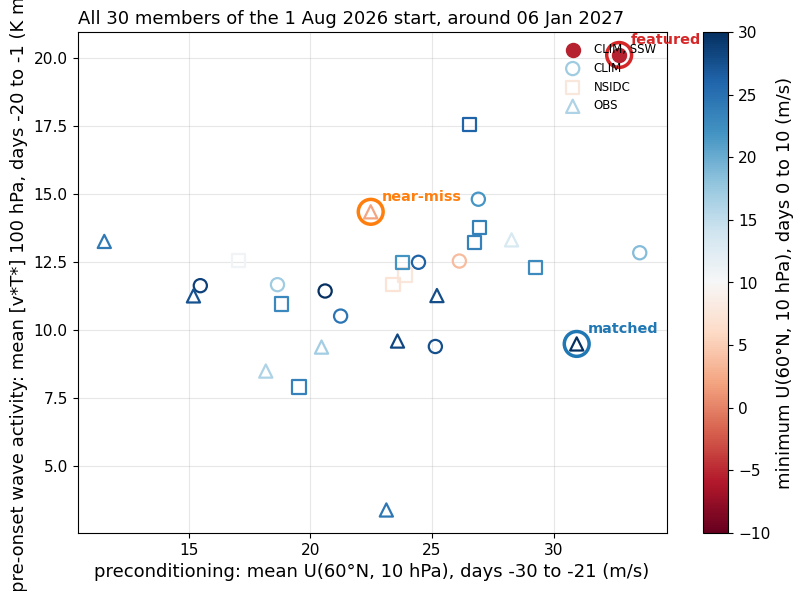

Members with an SSW between days -10 and 10: 1 of 30


,predictor,outcome,Spearman r,p,n
0,pre-onset heat flux,minimum U60,-0.393,0.032,30
1,preconditioning U60,minimum U60,-0.104,0.585,30
2,pre-onset heat flux,preconditioning U60,0.426,0.019,30


In [10]:
from scipy import stats

pre_c = window(u, *PRECOND_WINDOW).mean("time").to_series()
pre_w = window(vt, *RANK_WINDOW).mean("time").to_series()
out_min = window(u, *OUTCOME_WINDOW).min("time").to_series()
lo, hi = day0 + pd.Timedelta(days=OUTCOME_WINDOW[0] - 10), day0 + pd.Timedelta(days=OUTCOME_WINDOW[1])
ssw_near = set(ev[(ev["central_date"] >= lo) & (ev["central_date"] <= hi)]["series"])
rel = pd.DataFrame({"precond_u60": pre_c, "preonset_vt": pre_w, "outcome_min_u60": out_min})
rel["ssw"] = [m in ssw_near for m in rel.index]
rel["case"] = [sd.case_of(m) for m in rel.index]
rel.to_csv(DATA_DIR / f"mechanism_ensemble_relationship_{MONTH_NAMES[init]}_{feat.replace(':', '')}.csv")

fig, ax = plt.subplots(figsize=(9.5, 6.5))
markers = dict(zip(sorted(rel["case"].unique()), ("o", "s", "^")))
norm_o = plt.Normalize(-10, 30)
for case, g in rel.groupby("case"):
    for filled in (True, False):
        gg = g[g["ssw"] == filled]
        if gg.empty:
            continue
        kw = {"c": gg["outcome_min_u60"], "cmap": "RdBu", "norm": norm_o} if filled else              {"facecolors": "none", "edgecolors": plt.get_cmap("RdBu")(norm_o(gg["outcome_min_u60"].values))}
        ax.scatter(gg["precond_u60"], gg["preonset_vt"], s=90, marker=markers[case], lw=1.6, zorder=3,
                   label=f"{case.replace('Reanalysis-', '')}{', SSW' if filled else ''}", **kw)
for role, m in MEMBERS.items():
    ax.scatter(rel.loc[m, "precond_u60"], rel.loc[m, "preonset_vt"], s=320, facecolors="none", edgecolors=ROLES[role],
               lw=2.5, zorder=4)
    ax.annotate(role, (rel.loc[m, "precond_u60"], rel.loc[m, "preonset_vt"]), xytext=(8, 8), textcoords="offset points",
                color=ROLES[role], fontweight="bold", fontsize=fontz * 0.8)
sm = plt.cm.ScalarMappable(norm=norm_o, cmap="RdBu")
fig.colorbar(sm, ax=ax, label=f"minimum U(60°N, 10 hPa), days {OUTCOME_WINDOW[0]} to {OUTCOME_WINDOW[1]} (m/s)")
ax.set_xlabel(f"preconditioning: mean U(60°N, 10 hPa), days {PRECOND_WINDOW[0]} to {PRECOND_WINDOW[1]} (m/s)")
ax.set_ylabel(f"pre-onset wave activity: mean [v*T*] 100 hPa, days {RANK_WINDOW[0]} to {RANK_WINDOW[1]} (K m/s)")
ax.set_title(f"All {len(rel)} members of the 1 {MONTH_NAMES[init]} {YEAR} start, around {day0:%d %b %Y}", loc="left")
ax.legend(fontsize=fontz * 0.65, frameon=False, loc="upper right")
ax.grid(alpha=0.3)
save(fig, "mechanism", "ensemble_relationship", MONTH_NAMES[init], feat.replace(":", ""))
plt.show()

rows = []
for x, name in (("preonset_vt", "pre-onset heat flux"), ("precond_u60", "preconditioning U60")):
    r, p = stats.spearmanr(rel[x], rel["outcome_min_u60"])
    rows.append({"predictor": name, "outcome": "minimum U60", "Spearman r": r, "p": p, "n": len(rel)})
r, p = stats.spearmanr(rel["preonset_vt"], rel["precond_u60"])
rows.append({"predictor": "pre-onset heat flux", "outcome": "preconditioning U60", "Spearman r": r, "p": p, "n": len(rel)})
print(f"Members with an SSW between days {OUTCOME_WINDOW[0] - 10} and {OUTCOME_WINDOW[1]}: {len(ssw_near)} of {len(rel)}")
display(pd.DataFrame(rows).round(3))

### 5. Pre-onset 10-hPa height

Mean 10-hPa height of each member over the `PRE_WINDOWS` and the first days after onset: raw E3SM contours
(fixed levels) and the anomaly from the start's climatology (shading; `CLIM_METHOD`). Map orientation:
North America at the bottom, Europe on the right, Asia at the top, the Pacific on the left.

/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_s2d_proc/diagnostic/util/strat_case.py:630: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 61. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(path, chunks={"time": 61})    # lazy: about 0.3 GB per case and start


/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_s2d_proc/diagnostic/util/strat_case.py:630: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 61. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(path, chunks={"time": 61})    # lazy: about 0.3 GB per case and start


/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_s2d_proc/diagnostic/util/strat_case.py:630: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 61. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(path, chunks={"time": 61})    # lazy: about 0.3 GB per case and start


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9g_ssw_mechanism/figures/fig_mechanism_preonset_maps_aug_reanalysis_clim9.png


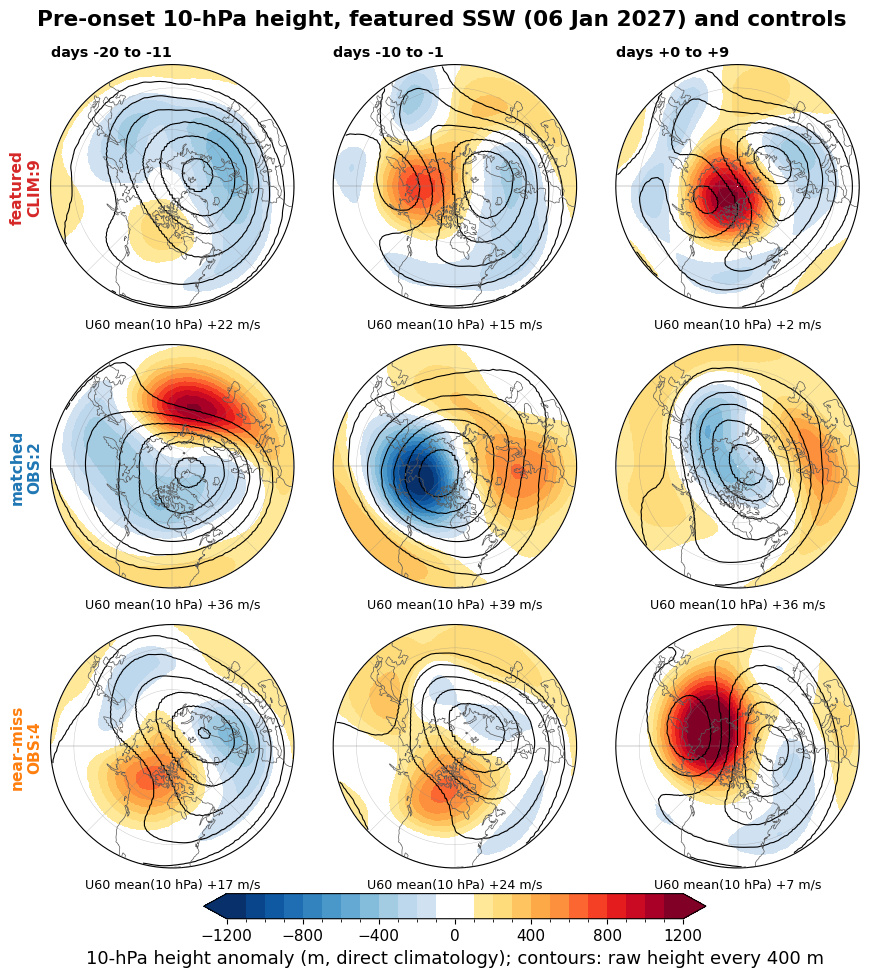

CPU times: user 30.2 s, sys: 3.14 s, total: 33.3 s
Wall time: 2min 19s


In [11]:
%%time
maps = sc.pooled_daily_maps(SIMULATION_ROOT, MAP_FILE, POOL, YEAR, init, mode=derivation_mode)
win_days = pd.date_range(day0 + pd.Timedelta(days=EVENT_WINDOW[0]), day0 + pd.Timedelta(days=EVENT_WINDOW[1]), freq="D")
win_days = win_days[win_days.isin(pd.DatetimeIndex(maps["time"].values))]
raw = maps.sel(member=list(MEMBERS.values()), time=win_days.values).sel(lat=slice(LAT_MIN - 0.01, 90.0)).load()
clim = sc.map_lead_climatology(POOL, YEAR, init, maps, win_days.values, method=CLIM_METHOD, lat_min=LAT_MIN, mode="auto").load()
anom = raw - clim
map_windows = PRE_WINDOWS + [(0, 9)]
fig, axes = plt.subplots(len(MEMBERS), len(map_windows), figsize=(3.6 * len(map_windows), 3.7 * len(MEMBERS)),
                         subplot_kw={"projection": vp.PROJ}, squeeze=False, gridspec_kw={"hspace": 0.15, "wspace": 0.04})
for r, (role, m) in enumerate(MEMBERS.items()):
    for c, (lo, hi) in enumerate(map_windows):
        sel = slice(day0 + pd.Timedelta(days=lo), day0 + pd.Timedelta(days=hi))
        st = vp.setup_map(axes[r, c], f"days {lo:+d} to {hi:+d}" if r == 0 else "", lat_min=LAT_MIN, color="k",
                          title_size=fontz * 0.8, badge_size=fontz * 0.7)
        uu = float(u.sel(member=m, time=sel).mean())
        vp.fill_map(axes[r, c], st, anom.sel(member=m, time=sel).mean("time"), raw.sel(member=m, time=sel).mean("time"),
                    style=STYLE, total_levels=STYLE["line_levels"], **vp.u60_badge(uu, "U60 mean"))
        if c == 0:
            axes[r, c].text(-0.1, 0.5, f"{role}\n{m.replace('Reanalysis-', '')}", transform=axes[r, c].transAxes,
                            rotation=90, ha="center", va="center", color=ROLES[role], fontweight="bold", fontsize=fontz * 0.85)
levels, cmap, norm = vp.shading(STYLE)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, orientation="horizontal", fraction=0.03, pad=0.03,
                  shrink=0.6, extend="both", ticks=np.arange(-1200, 1201, 400))
cb.set_label(f"10-hPa height anomaly (m, {CLIM_METHOD} climatology); contours: raw height every {STYLE['line']:g} m")
fig.suptitle(f"Pre-onset 10-hPa height, featured SSW ({day0:%d %b %Y}) and controls", y=0.93, fontweight="bold")
save(fig, "mechanism", "preonset_maps", MONTH_NAMES[init], feat.replace(":", ""))
plt.show()

### 6. Side-by-side animation

The three members over `EVENT_WINDOW`, one frame per day, above their U(60°N, 10 hPa) timelines.

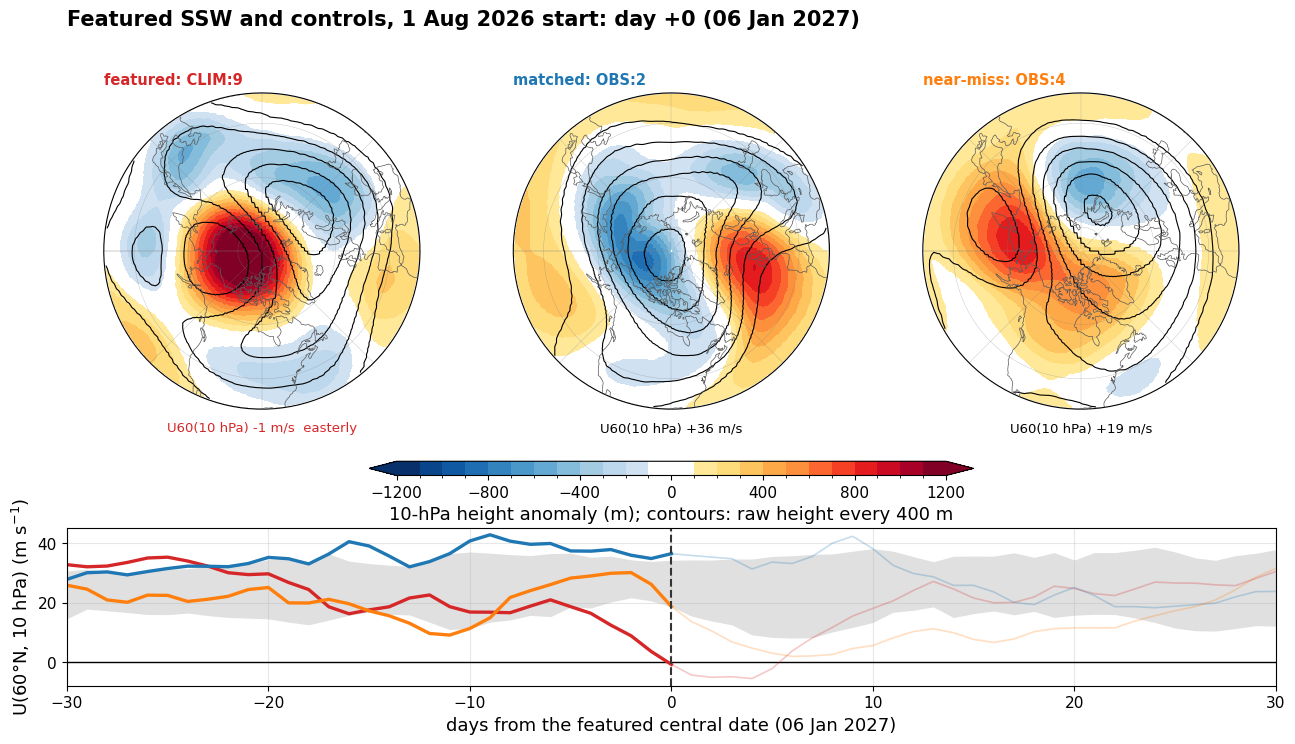

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9g_ssw_mechanism/figures/fig_mechanism_animation_aug_reanalysis_clim9.gif (7.6 MB)


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9g_ssw_mechanism/figures/fig_mechanism_animation_aug_reanalysis_clim9.webm (2.2 MB)
CPU times: user 3min 58s, sys: 5.68 s, total: 4min 4s
Wall time: 7min 34s


In [12]:
%%time
fig = plt.figure(figsize=(13.0, 7.6))
gs = fig.add_gridspec(3, 3, height_ratios=(1.0, 0.045, 0.5), hspace=0.32, wspace=0.05, left=0.05, right=0.98, top=0.86, bottom=0.08)
panels = {}
for k, (role, m) in enumerate(MEMBERS.items()):
    ax = fig.add_subplot(gs[0, k], projection=vp.PROJ)
    panels[role] = (ax, vp.setup_map(ax, f"{role}: {m.replace('Reanalysis-', '')}", lat_min=LAT_MIN, color=ROLES[role]))
cax = fig.add_subplot(gs[1, :])
pos = cax.get_position()
cax.set_position([pos.x0 + pos.width * 0.25, pos.y0, pos.width * 0.5, pos.height])
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal", extend="both",
             ticks=np.arange(-1200, 1201, 400)).set_label("10-hPa height anomaly (m); contours: raw height every 400 m")
axt = fig.add_subplot(gs[2, :])
s = on_lags(u)
q = s.quantile([0.1, 0.9], "member")
axt.fill_between(lags, q.isel(quantile=0), q.isel(quantile=1), color="0.88", lw=0)
axt.axhline(0, color="k", lw=1)
lines = {}
for role, m in MEMBERS.items():
    axt.plot(lags, s.sel(member=m), color=ROLES[role], lw=1.2, alpha=0.25)
    lines[role] = axt.plot([], [], color=ROLES[role], lw=2.4)[0]
cursor = axt.axvline(lags[0], color="0.2", ls="--")
axt.set_xlim(lags[0], lags[-1])
axt.set_xlabel(f"days from the featured central date ({day0:%d %b %Y})")
axt.set_ylabel("U(60°N, 10 hPa) (m s$^{-1}$)")
axt.grid(alpha=0.3)
title = fig.suptitle("", x=0.05, ha="left", y=0.97, fontsize=15, fontweight="bold")


def draw(lag):
    t = day0 + pd.Timedelta(days=int(lag))
    title.set_text(f"Featured SSW and controls, 1 {MONTH_NAMES[init]} {YEAR} start: day {int(lag):+d} ({t:%d %b %Y})")
    for role, m in MEMBERS.items():
        ax, st = panels[role]
        tn = np.datetime64(t, "ns")
        if tn in raw["time"].values:
            vp.fill_map(ax, st, anom.sel(member=m, time=tn), raw.sel(member=m, time=tn), style=STYLE,
                        total_levels=STYLE["line_levels"], **vp.u60_badge(float(u.sel(member=m, time=tn))))
        lines[role].set_data(lags[lags <= lag], s.sel(member=m).values[lags <= lag])
    cursor.set_xdata([lag, lag])
    return []


draw(0)
fig.savefig(FIGDIR / figure_filename("mechanism", "preview", MONTH_NAMES[init], feat.replace(":", ""), ext="png"), dpi=fig_dpi)
plt.show()
video_ext, video = vp.video_writer(FPS)
writers = {"gif": ("gif", lambda: animation.PillowWriter(fps=FPS)), "video": (video_ext, video)}
anim = animation.FuncAnimation(fig, draw, frames=list(lags) + [lags[-1]] * HOLD, blit=False, cache_frame_data=False)
for fmt in ANIM_FORMATS:
    ext, writer = writers[fmt]
    if writer is None:
        continue
    path = FIGDIR / figure_filename("mechanism", "animation", MONTH_NAMES[init], feat.replace(":", ""), ext=ext)
    anim.save(path, writer=writer(), dpi=ANIM_DPI)
    print(f"{path} ({path.stat().st_size / 1e6:.1f} MB)")
plt.close(fig)

### How to read these results

* **Featured vs matched.** Members that start from a similar vortex (`MATCH_WINDOW`) can follow very
  different wave-activity histories and wind evolutions: the initial U(60°N, 10 hPa) alone does not set the
  outcome. A featured member with repeated heat-flux pulses before onset, against a matched member with
  little, is consistent with enhanced upward planetary-wave activity contributing to the disruption.
* **Featured vs near-miss.** Comparable flux peaks can differ in timing and duration; forcing after the
  featured onset cannot explain its earlier reversal. Compare accumulated pre-onset wave activity and the
  evolving vortex state, not only peak flux.
* **Wording.** The 100-hPa heat flux is a *prominent diagnostic contrast* and a *proxy* for upward wave
  activity. Pulses that *precede* episodes of weakening are consistent with wave-driven deceleration; the
  lag is not quantified here. Ranks ("largest of the members") come from the individual-member values in
  section 3. Polar-cap warming *accompanies* the disruption; the maps (section 5) are needed to tell a
  displacement from broader warming. Magnitudes are not compared with ERA5 here (different sampling and no
  matched averaging). A polar-cap warming without a U(60°N) reversal is described as such; a formal minor-warming
  classification needs further diagnostics.
* **Representativeness.** Section 4 says whether the featured member is one instance of an ensemble
  relationship or one illustrative trajectory.